In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)
group_a = pd.DataFrame({'group': 'A', 'converted': np.random.binomial(1, 0.12, 150)})
group_b = pd.DataFrame({'group': 'B', 'converted': np.random.binomial(1, 0.18, 150)})
df_ab = pd.concat([group_a, group_b])

stats = df_ab.groupby('group')['converted'].agg(['count', 'mean'])
stats.columns = ['n', 'conversion_rate']

stats['se'] = np.sqrt(stats['conversion_rate'] * (1 - stats['conversion_rate']) / stats['n'])
stats['margin_of_error'] = 1.96 * stats['se']
stats['ci_lower'] = stats['conversion_rate'] - stats['margin_of_error']
stats['ci_upper'] = stats['conversion_rate'] + stats['margin_of_error']

conv_a = stats.loc['A', 'conversion_rate']
conv_b = stats.loc['B', 'conversion_rate']
abs_diff = conv_b - conv_a
rel_change = (conv_b - conv_a) / conv_a

print("Статистика груп:")
print(stats[['conversion_rate', 'ci_lower', 'ci_upper']])
print(f"\nАбсолютна різниця: {abs_diff:.4f}")
print(f"Відносна зміна: {rel_change:.2%}")

Статистика груп:
       conversion_rate  ci_lower  ci_upper
group                                     
A             0.120000  0.067995  0.172005
B             0.193333  0.130134  0.256532

Абсолютна різниця: 0.0733
Відносна зміна: 61.11%


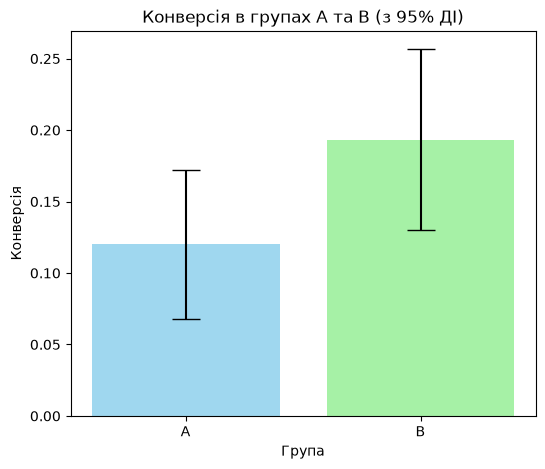

In [3]:
plt.figure(figsize=(6, 5))
plt.bar(stats.index, stats['conversion_rate'], yerr=stats['margin_of_error'], capsize=10, color=['skyblue', 'lightgreen'], alpha=0.8)
plt.title('Конверсія в групах A та B (з 95% ДІ)')
plt.ylabel('Конверсія')
plt.xlabel('Група')
plt.show()